# Лабораторная работа №3: Трансформеры

**Студент:** Максимова Алина

**Группа:** 6233-010402D

## Цель
Познакомиться с архитектурой Transformer и её применением для задач NLP (классификация текста, машинный перевод).

## Теория
- Архитектура Transformer: encoder-decoder, self-attention.
- Различия BERT и GPT.

## Задания
1. Использовать BERT (через HuggingFace).
2. Провести fine-tuning на IMDb dataset.
3. Сравнить результаты с baseline (логистическая регрессия + TF-IDF).
4. Оценить точность и построить confusion matrix.

## Вопросы
1. Зачем нужен positional encoding?
2. В чём отличие encoder-only и decoder-only моделей?
3. Почему трансформеры лучше RNN в NLP?

## Отчёт
- Краткое описание выбранной задачи.
- Результаты fine-tuning.
- Сравнение с baseline.
- Ответы на вопросы.

## Теория

#### ***Архитектура Transformer: encoder-decoder, self-attention.***

**encoder-decoder**

Transformer — нейросетевая архитектура без рекуррентности, основанная на внимании. Исходно состоит из encoder и decoder.

Encoder получает входную последовательность и строит её контекстные представления.

Decoder генерирует выходную последовательность авторегрессионно.

Cross-attention позволяет decoder обращаться к encoder: запросы из decoder, ключи/значения — из encoder.

Позиционное кодирование добавляет информацию о порядке токенов, так как self-attention сам по себе порядок не учитывает.

**self-attention**

Self-attention — механизм, при котором каждый токен строит представление с учётом всех (или разрешённых) токенов последовательности.

Для каждого токена формируются:

Query (Q) — «что я ищу»;

Key (K) — «что я предлагаю»;

Value (V) — «какую информацию передаю».

Веса внимания:

$$ Attention(Q, K, V) = softmax\left(\frac{QK^T}{\sqrt{d_k}}\right)V $$


Multi-head attention — несколько параллельных «голов» внимания, каждая учится своим зависимостям; результаты конкатенируются и проецируются.

Masked self-attention запрещает обращение к будущим токенам — используется в decoder/GPT.

Bi-directional self-attention видит всю последовательность — используется в encoder/BERT.

#### ***Различия BERT и GPT*.**

BERT:
- тип архитектуры - Encoder-only;
- основная задача - Masked Language Modeling;
- полное self-attention;
- основное применение - понимание текста (классификация, NER, QA, эмбеддинги);
- не предназначен для свободной генерации.

GPT:
- тип архитектуры - Decoder-only;
- основная задача - Causal Language Modeling;
- masked self-attention;
- основное применение - генерация текста, диалоги, completion, in-context learning;
- основная сила — авторегрессионная генерация.

Идея работы: оценить тональность текста (бинарная).

Необходимо сраванить:

классическая модель с логистическая регрессия + TF-IDF

fine-tuning предобученная модель-трансфорер BERT

## Установка необходимых библиотек:

In [1]:
!pip install -q transformers datasets scikit-learn matplotlib seaborn

## Библиотеки

In [21]:
import torch
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_recall_fscore_support
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer,  DataCollatorWithPadding

## Проверка доступности GPU

In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используемое устройство: {device}")
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Используемое устройство: cuda
Tesla T4


## Загрузка и подготовка данных

In [23]:
dataset = load_dataset("stanfordnlp/imdb")

full_train = dataset["train"]
split = full_train.train_test_split(test_size=0.2, seed=42)
train_data = split["train"]
val_data   = split["test"]
test_data  = dataset["test"]

print(f"Train (80%):      {len(train_data)}")
print(f"Validation (20%): {len(val_data)}")
print(f"Test (IMDb test): {len(test_data)}")
print(f"Пример отзыва: {train_data['text'][0][:200]}...")
print(f"Метка: {train_data['label'][0]}")

Train (80%):      20000
Validation (20%): 5000
Test (IMDb test): 25000
Пример отзыва: Stage adaptations often have a major fault. They often come out looking like a film camera was simply placed on the stage (Such as "Night Mother"). Sidney Lumet's direction keeps the film alive, which...
Метка: 1


In [24]:
# Распределение классов
train_df = pd.DataFrame({"label": train_data["label"]})
val_df   = pd.DataFrame({"label": val_data["label"]})
print("\nРаспределение меток в train:")
print(train_df["label"].value_counts(normalize=True).round(3))
print("Распределение меток в validation:")
print(val_df["label"].value_counts(normalize=True).round(3))


Распределение меток в train:
label
0    0.5
1    0.5
Name: proportion, dtype: float64
Распределение меток в validation:
label
1    0.501
0    0.499
Name: proportion, dtype: float64


## Baseline — Логистическая регрессия + TF-IDF

In [25]:
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(train_data["text"])
X_test_tfidf  = vectorizer.transform(test_data["text"])

baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train_tfidf, train_data["label"])

baseline_preds = baseline_model.predict(X_test_tfidf)
baseline_accuracy = accuracy_score(test_data["label"], baseline_preds)

print(f"\nBaseline (LogReg + TF-IDF) Accuracy: {baseline_accuracy:.4f}\n")
print("Classification Report (Baseline):")
print(classification_report(
    test_data["label"], baseline_preds,
    target_names=["Negative", "Positive"], digits=4,
))


Baseline (LogReg + TF-IDF) Accuracy: 0.8901

Classification Report (Baseline):
              precision    recall  f1-score   support

    Negative     0.8938    0.8854    0.8896     12500
    Positive     0.8864    0.8948    0.8906     12500

    accuracy                         0.8901     25000
   macro avg     0.8901    0.8901    0.8901     25000
weighted avg     0.8901    0.8901    0.8901     25000



## Fine-tuning BERT

Токенезатор и модель:

In [26]:
model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2).to(device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Токенизация и подготовка датасетов:

In [27]:
def tokenize_function(examples):
    return tokenizer(examples["text"], padding="max_length", truncation=True, max_length=256)

train_dataset = train_data.map(tokenize_function, batched=True)
val_dataset   = val_data.map(tokenize_function, batched=True)
test_dataset  = test_data.map(tokenize_function, batched=True)

def prepare_dataset(ds):
    ds = ds.remove_columns(["text"])
    if "label" in ds.column_names:
        ds = ds.rename_column("label", "labels")
    ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
    return ds

train_dataset = prepare_dataset(train_dataset)
val_dataset   = prepare_dataset(val_dataset)
test_dataset  = prepare_dataset(test_dataset)

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Collator и метрики:

In [28]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer, padding="longest", return_tensors="pt"
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="binary"
    )
    return {"accuracy": acc, "f1": f1, "precision": precision, "recall": recall}

Аргументы обучения:

In [29]:
training_args = TrainingArguments(
    output_dir="./bert-imdb-full",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_steps=200,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    fp16=torch.cuda.is_available(),
    report_to="none",
)


Trainer и обучение (на основе экспериментов было выяснено, что наиболее оптимальное значение достигается при 2 эпохах, так как именно при этом значении достигается максимальная точность (0,917) при небольшом увеличении validation loss (+ ~0,04), при дальнейшнем обучении модель бы увеличивала значение loss, что свидетельствовало о переобучении, что привело к ухудшению значения метрик качества):

In [30]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.226873,0.242524,0.910400,0.908906,0.926617,0.891860
2,0.148232,0.285300,0.917200,0.917200,0.919407,0.915004


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=2500, training_loss=0.2227580295562744, metrics={'train_runtime': 676.5466, 'train_samples_per_second': 59.124, 'train_steps_per_second': 3.695, 'total_flos': 5262221107200000.0, 'train_loss': 0.2227580295562744, 'epoch': 2.0})

## Сравнение и визуализация Confusion Matrix

BERT Fine-tuned — Accuracy (test): 0.9196
Classification Report (BERT):
              precision    recall  f1-score   support

    Negative     0.9253    0.9128    0.9190     12500
    Positive     0.9140    0.9263    0.9201     12500

    accuracy                         0.9196     25000
   macro avg     0.9196    0.9196    0.9196     25000
weighted avg     0.9196    0.9196    0.9196     25000


Baseline (LogReg + TF-IDF) — Accuracy (test): 0.8901
Classification Report (Baseline):
              precision    recall  f1-score   support

    Negative     0.8938    0.8854    0.8896     12500
    Positive     0.8864    0.8948    0.8906     12500

    accuracy                         0.8901     25000
   macro avg     0.8901    0.8901    0.8901     25000
weighted avg     0.8901    0.8901    0.8901     25000



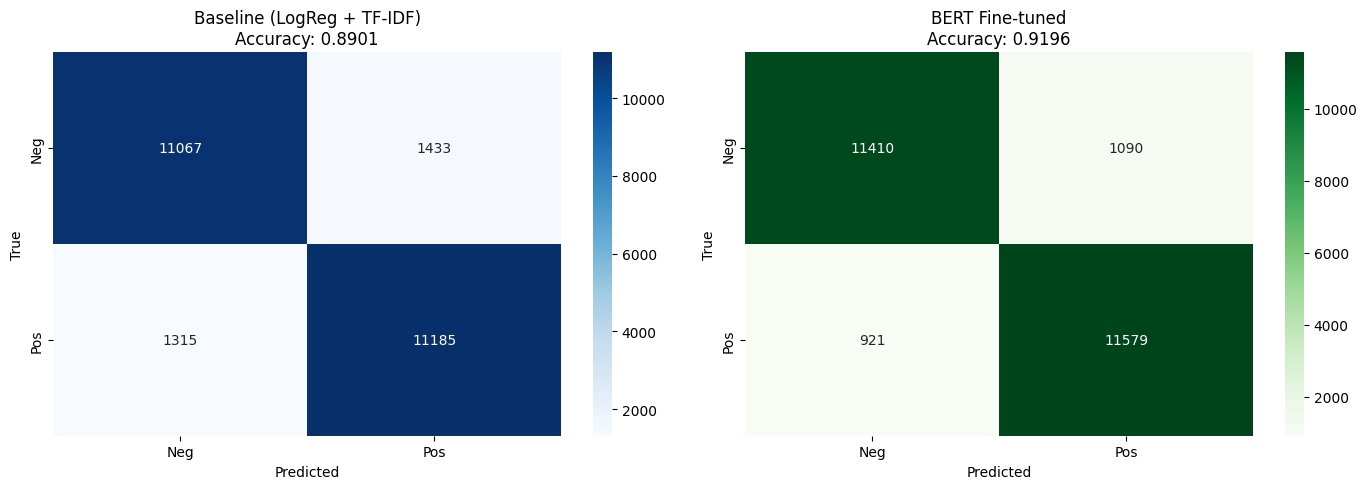


Сводная таблица:
                     Model  Accuracy  Precision  Recall  F1 (binary)
Baseline (TF-IDF + LogReg)    0.8901     0.8864  0.8948       0.8906
         BERT (fine-tuned)    0.9196     0.9140  0.9263       0.9201

Accuracy (BERT − Baseline) = +0.0295 


In [34]:
bert_output = trainer.predict(test_dataset)
bert_preds  = np.argmax(bert_output.predictions, axis=-1)
true_labels = bert_output.label_ids

bert_accuracy = accuracy_score(true_labels, bert_preds)
bert_results  = {"eval_accuracy": bert_accuracy}

print("=" * 62)
print(f"BERT Fine-tuned — Accuracy (test): {bert_accuracy:.4f}")
print("=" * 62)
print("Classification Report (BERT):")
print(classification_report(true_labels, bert_preds,
                            target_names=["Negative", "Positive"],
                            digits=4))


assert len(true_labels) == len(baseline_preds), (
    f"Разная длина: true_labels={len(true_labels)}, "
    f"baseline_preds={len(baseline_preds)}"
)
assert (true_labels == np.array(test_data["label"])).all(), (
    "Порядок меток test_dataset и test_data не совпадает! "
)
print("\n" + "=" * 62)
print(f"Baseline (LogReg + TF-IDF) — Accuracy (test): {baseline_accuracy:.4f}")
print("=" * 62)
print("Classification Report (Baseline):")
print(classification_report(true_labels, baseline_preds,
                            target_names=["Negative", "Positive"],
                            digits=4))

# Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_baseline = confusion_matrix(true_labels, baseline_preds)
sns.heatmap(cm_baseline, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
axes[0].set_title(f"Baseline (LogReg + TF-IDF)\nAccuracy: {baseline_accuracy:.4f}")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")

cm_bert = confusion_matrix(true_labels, bert_preds)
sns.heatmap(cm_bert, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
axes[1].set_title(f"BERT Fine-tuned\nAccuracy: {bert_accuracy:.4f}")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")

plt.tight_layout()
plt.show()

# Таблица сравнения
p_b, r_b, f1_b, _ = precision_recall_fscore_support(
    true_labels, baseline_preds, average="binary")
p_t, r_t, f1_t, _ = precision_recall_fscore_support(
    true_labels, bert_preds,     average="binary")

comparison = pd.DataFrame({
    "Model":       ["Baseline (TF-IDF + LogReg)", "BERT (fine-tuned)"],
    "Accuracy":    [baseline_accuracy,             bert_accuracy],
    "Precision":   [p_b,                           p_t],
    "Recall":      [r_b,                           r_t],
    "F1 (binary)": [f1_b,                          f1_t],
}).round(4)

print("\nСводная таблица:")
print(comparison.to_string(index=False))

delta = bert_accuracy - baseline_accuracy
print(f"\nAccuracy (BERT − Baseline) = {delta:+.4f} ")

**Выводы:**

Fine-tuning BERT показал преимущество над классической моделью по метрикам качества. Прирост аccuracy составил 2,95. В данном случае это ощутимая разница, так как базовые модели как TF-IDF уже показывают высокие результаты.

За счет перехода на контекстные эмбеддинги BERT существенно снизил количество неверных предсказаний. Ложноположительные срабатывания (FP) снизились с 1433 до 1090. Ложноотрицательные срабатывания (FN) снизились с 1315 до 921. То есть BERT сделал на 737 ошибок меньше.

Обе модели показали себя сбалансированно на обоих классах (нет сильного перекоса в сторону negative или positive).

Минус BERT: базовая модель (LogReg + TF-IDF) обучается за секунды и на CPU, а BERT требует GPU и значительно больше времени.

Плюс BERT: сокращение ошибок (на 737 меньше, чем у базовой модели) оправдывает использование BERT в задачах, где максимально важна точность анализа тональности.

## Вопросы
#### **Зачем нужен positional encoding?**
Self-attention сам по себе не учитывает порядок токенов. Positional encoding добавляет к эмбеддингам токенов сведения об их позиции, чтобы модель различала
порядок слов, расстояние между ними, структуру последовательности.

Варианты:

абсолютные — синусоидальные или обучаемые векторы позиций;

относительные — кодируют расстояние между токенами;

RoPE и др. — встраивают позицию в механизм внимания.


#### **В чём отличие encoder-only и decoder-only моделей?**

**Encoder-only**

* Внимание полное, двунаправленное
* Видит всю последовательность сразу
* Примеры: BERT, RoBERTa
* Используют для понимание текста, классификация, NER, QA, эмбеддинги

**Decoder-only**

* Внимание сausal / masked, только на прошлые токены
* Видит только левый контекст
* Примеры: GPT, LLaMA
* Основная функция генерация
* Используют для генерации, диалогов, completion, in-context learning

#### **Почему трансформеры лучше RNN в NLP?**

1. RNN обрабатывает токены последовательно, Transformer — все позиции параллельно. Это лучше использует GPU и ускоряет обучение.

2. В RNN информация идёт через скрытые состояния шаг за шагом, сигнал затухает. В self-attention между любыми токенами есть прямой путь длиной O(1).

3. Transformer хорошо масштабируется по данным и параметрам.

4. Разные головы могут учить разные типы связей: синтаксис, кореферентность, локальные/глобальные зависимости.